 ================================================================================================================================================================================================

 NOTEBOOK 04 — ZHU GUARDED LWC RETRIEVAL (CLEANED)

 ================================================================================================================================================================================================



 Pipeline: load data -> 30 s time-average DWR -> dDWR/dH diagnostic ->

 Zhu **guarded** retrieval -> LWC quality checks -> LWP (3 checks only, for later comparison)



 Removed in this cleanup (all still recoverable from notebook history if needed):

   - 60 s time-averaging branch

   - Raw / un-averaged Zhu retrieval exploration (superseded by the 30 s branch, which is

     what feeds the guarded retrieval anyway)

   - Most LWP diagnostics — kept only: general LWP time series, LWP closure scatter,

     and the "spot check three profiles" comparison

   - 500-1500 m windowed retrieval experiment

   - common_mask (C1/C2) redundant second retrieval pass

 ================================================================================================================================================================================================

 ## 0. Setup

In [2]:
from pathlib import Path

retrieval_dir = Path("../src/radar_lwc/retrieval").resolve()
print(retrieval_dir)
print(list(retrieval_dir.glob("*.py")))


C:\Projects\Masterarbeit\dual_freq_radar_lwc\src\radar_lwc\retrieval
[WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/average_ze_time.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/ddwr_dh.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/dielectric.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/dq_retrieval.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/gas_attenuation.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/kappa_liquid.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/rpg_chirp_table.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/zhu.py')]


In [3]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

sys.path.append(str(Path("../src").resolve()))

# Preprocessing
from radar_lwc.preprocessing.align import align_to_reference_time
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity

# Retrieval
from radar_lwc.retrieval.average_ze_time import avg_ze_time
from radar_lwc.retrieval.ddwr_dh import compute_ddwr_dh
from radar_lwc.retrieval.dielectric import epsilon_water_liebe1989
from radar_lwc.retrieval.kappa_liquid import kappa_liquid
from radar_lwc.retrieval.zhu import retrieve_lwc_zhu


In [4]:
Processed_Dataset = "20261001_pallas_interpolation_CLARA"

In [5]:
in_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_input_4km_alpha_kappa_calculated.nc")
ds_retrieval = xr.open_dataset(in_path)
print(ds_retrieval)


<xarray.Dataset> Size: 609MB
Dimensions:          (Time: 30216, range: 237)
Coordinates:
  * Time             (Time) datetime64[ns] 242kB 2026-10-01T00:43:14.05295848...
  * range            (range) float64 2kB 104.3 119.3 ... 3.952e+03 3.986e+03
Data variables: (12/16)
    Ze_W             (Time, range) float64 57MB ...
    Ze_Ka            (Time, range) float64 57MB ...
    T_cloud          (Time, range) float64 57MB ...
    LWP              (Time) float32 121kB ...
    DWR              (Time, range) float64 57MB ...
    cloud_mask       (Time, range) bool 7MB ...
    ...               ...
    alpha_W          (Time, range) float64 57MB ...
    alpha_Ka         (Time, range) float64 57MB ...
    kappa_W          (Time, range) float64 57MB ...
    kappa_Ka         (Time, range) float64 57MB ...
    MeanVel_W        (Time, range) float64 57MB ...
    MeanVel_Ka       (Time, range) float64 57MB ...
Attributes:
    description:  Prepared inputs for Zhu et al. (2019) LWC retrieval with al

 ================================================================================================================================================================================================

 ## 1. Time averaging (30 s only)



 Averaging Ze in linear space before forming DWR beats down per-gate DWR noise, which is a

 prerequisite for a physically meaningful dDWR/dH gradient. 30 s was kept as the working

 resolution; 60 s is dropped for now (barely changed the diagnostics — restore quickly by

 copying the `window_s=60` block back in if a comparison is ever needed again).

 ================================================================================================================================================================================================

In [6]:
m = ds_retrieval["common_mask"].fillna(0).astype(bool)      # same profiles for both radars
ze_ka_avg = avg_ze_time(ds_retrieval["Ze_Ka"].where(m).sel(range=slice(0, 4000)), window_s=30)
ze_w_avg  = avg_ze_time(ds_retrieval["Ze_W"].where(m).sel(range=slice(0, 4000)),  window_s=30)

dwr_2km_smoothed = ze_ka_avg - ze_w_avg
dwr_2km_smoothed.name = "DWR"


In [7]:
# %% 1 dB gate-to-gate filter (Socuellamos): replace spikes by linear interpolation
gate_threshold = 1.0  # dB

def despike_1d(dwr_1d, threshold=1.0):
    """
    dwr_1d: 1D array along range for a single time step.
    A gate i is an outlier if it differs from BOTH neighbours by more than
    `threshold` dB in the same direction (i.e. it's a spike relative to a
    smooth profile) -> replaced by linear interpolation between i-1 and i+1.
    """
    out = dwr_1d.copy()
    n = len(dwr_1d)
    for i in range(1, n - 1):
        left = dwr_1d[i] - dwr_1d[i - 1]
        right = dwr_1d[i] - dwr_1d[i + 1]
        is_spike = (
            np.abs(left) > threshold
            and np.abs(right) > threshold
            and np.sign(left) == np.sign(right)   # same direction on both sides
        )
        if is_spike and not (np.isnan(dwr_1d[i - 1]) or np.isnan(dwr_1d[i + 1]) or np.isnan(dwr_1d[i])):
            out[i] = dwr_1d[i - 1] + (dwr_1d[i + 1] - dwr_1d[i - 1]) * 0.5  # linear interp
    return out

dwr_2km_filt = xr.apply_ufunc(
    despike_1d,
    dwr_2km_smoothed,
    input_core_dims=[["range"]],
    output_core_dims=[["range"]],
    kwargs={"threshold": gate_threshold},
    vectorize=True,
)
dwr_2km_filt.name = "DWR"
dwr_2km_filt.attrs = dwr_2km_smoothed.attrs

n_replaced = int((np.abs(dwr_2km_filt - dwr_2km_smoothed) > 1e-9).sum())
print(f"Gates replaced by interpolation: {n_replaced} "
      f"({n_replaced / dwr_2km_smoothed.size:.2%} of all gates)")

Gates replaced by interpolation: 3043 (0.04% of all gates)


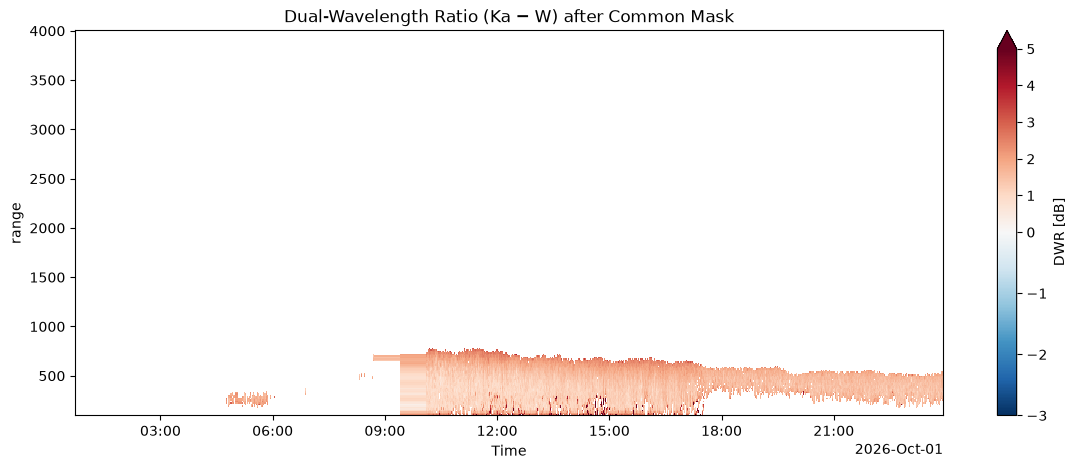

In [8]:
from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(14, 5))

dwr_2km_filt.where(ds_retrieval["common_mask"]).plot(
    x="Time",
    y="range",
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=5),
    ax=ax,
    cbar_kwargs={"label": "DWR [dB]"}
)

ax.set_title("Dual-Wavelength Ratio (Ka − W) after Common Mask")
plt.show()

 ## 2. dDWR/dH diagnostic (30 s smoothed input)



 This is the key sanity check before trusting the gradient-based retrieval: how much of the

 in-cloud gradient is still noise (negative or unphysically large |dDWR/dH|)?

In [9]:
ddwr_dh_smoothed = compute_ddwr_dh(dwr_2km_filt, ds_retrieval["common_mask"], N_default=13)

vals = ddwr_dh_smoothed.where(ds_retrieval["common_mask"]).values.ravel()
vals = vals[np.isfinite(vals)]
print("After 30 s time-averaging:")
print(f"  Fraction dDWR/dh < 0:          {(vals < 0).mean():.2%}")
print(f"  Fraction |dDWR/dh| > 30 dB/km: {(np.abs(vals) > 30).mean():.2%}")
print(f"  median dDWR/dh:                {np.median(vals):.2f} dB/km")


After 30 s time-averaging:
  Fraction dDWR/dh < 0:          34.26%
  Fraction |dDWR/dh| > 30 dB/km: 1.02%
  median dDWR/dh:                1.63 dB/km


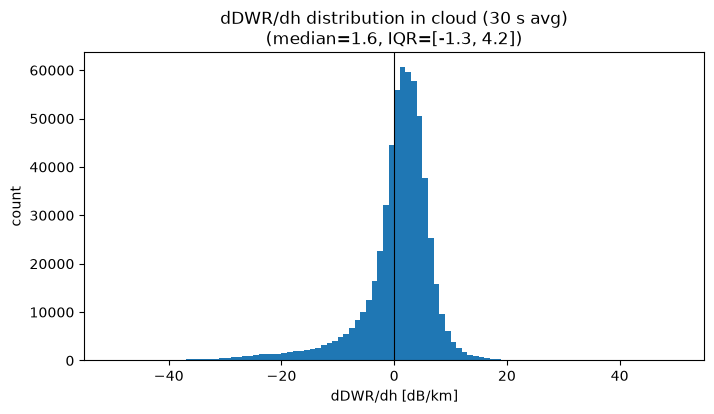

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(vals, bins=100, range=(-50, 50))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("dDWR/dh [dB/km]")
ax.set_ylabel("count")
ax.set_title(f"dDWR/dh distribution in cloud (30 s avg)\n"
             f"(median={np.median(vals):.1f}, "
             f"IQR=[{np.percentile(vals,25):.1f}, {np.percentile(vals,75):.1f}])")
plt.show()


 (Supporting context for the guard thresholds below — per-gate DWR noise estimate from

 vertical-neighbour differences.)

In [11]:
D = dwr_2km_filt.where(ds_retrieval["common_mask"]).values                 #Filtered DWR values where the common mask is True
diffs = D[:, 1:] - D[:, :-1]                                  # DWR(i+1)−DWR(i)   Subtracting the DWR value of the next gate from the current gate to get the difference between adjacent gates
diffs = diffs[np.isfinite(diffs)]               # Remove NaN
noise_estimate = np.std(diffs) / np.sqrt(2)      #standard deviation of the difference tells how widely these differences scatter. Signal is supposed to be the same in neighbouring gates, so difference should be zero. Rest is just noise. The Variance Difference is Var(Ni+1​−Ni​)= Var(Ni+1​)+Var(Ni​) = σ^2+σ^2 =2σ^2.Therefore: Std(Ni+1​−Ni​)=sqrt(2)*σ Finally: noise = std_difference / np.sqrt(2)
print(f"Estimated per-gate DWR noise: {noise_estimate:.2f} dB")
print(f"Median in-cloud DWR:          {float(dwr_2km_filt.where(ds_retrieval['common_mask']).median()):.2f} dB")
print(f"Signal across a 9-gate (~200 m) window at 5 dB/km: {5 * 0.20:.2f} dB")    # Comparison Noise and Signal across  Window


Estimated per-gate DWR noise: 0.26 dB
Median in-cloud DWR:          1.52 dB
Signal across a 9-gate (~200 m) window at 5 dB/km: 1.00 dB


In [12]:
print("dwr        :", dict(dwr_2km_filt.sizes), float(dwr_2km_filt["range"][-1]))
for v in ["common_mask", "kappa_W", "alpha_W", "Ze_Ka"]:
    print(f"{v:11s}:", dict(ds_retrieval[v].sizes), float(ds_retrieval[v]["range"][-1]))

dwr        : {'Time': 30216, 'range': 237} 3986.2431640625
common_mask: {'Time': 30216, 'range': 237} 3986.2431640625
kappa_W    : {'Time': 30216, 'range': 237} 3986.2431640625
alpha_W    : {'Time': 30216, 'range': 237} 3986.2431640625
Ze_Ka      : {'Time': 30216, 'range': 237} 3986.2431640625


In [13]:
mm = ds_retrieval["common_mask_raw"].fillna(0).astype(bool).values
multi = [p.sum() > 1 and np.diff(np.flatnonzero(p)).max() > 4 for p in mm]
print(f"profiles with a second layer (gap > 3 gates): {np.mean(multi):.1%}")

profiles with a second layer (gap > 3 gates): 0.4%


 ================================================================================================================================================================================================

 ## 3. Zhu Guarded retrieval



 Drop-in replacement for the plain gradient retrieval: overlap-averages the window fit and

 rejects windows that are too noisy (`max_window_std`) or produce an unphysical gradient

 (`max_ddwr_dh`), with `edge_pad` gates skipped near cloud base/top.

 ================================================================================================================================================================================================

In [14]:
def retrieve_lwc_zhu_guarded(
    dwr, kappa_w, kappa_ka, alpha_w, alpha_ka, common_mask,
    N_default=9,
    max_ddwr_dh=50.0,      # dB/km — physical ceiling on |dDWR/dh|
    max_window_std=3.0,    # dB    — reject noisy windows
    edge_pad=1,            # skip edge gates near cloud base/top
):
    """
    Zhu-style LWC retrieval with overlap averaging + sanity guards.
    Assumes dims ('Time', 'range'). Returns (LWC g/m^3, n_windows per gate).
    """
    h = dwr["range"].values.astype(float)
    D = dwr.values
    Kw, Kka = kappa_w.values, kappa_ka.values
    Aw, Aka = alpha_w.values, alpha_ka.values
    M = common_mask.values
    nt, nr = D.shape

    lwc_sum = np.zeros_like(D)
    lwc_cnt = np.zeros_like(D)

    for t in range(nt):
        cloud_idx = np.flatnonzero(M[t])
        if cloud_idx.size < 3:
            continue
        i0 = cloud_idx.min() + edge_pad
        i1 = cloud_idx.max() - edge_pad
        if i1 - i0 + 1 < 3:
            continue
        Nt = min(N_default, i1 - i0 + 1)

        for i in range(i0, i1 - Nt + 2):
            sl = slice(i, i + Nt)
            if not M[t, sl].all():
                continue
            dwin = D[t, sl]
            if not np.isfinite(dwin).all():
                continue
            if dwin.std() > max_window_std:
                continue
            a, b, _c = np.polyfit(h[sl], dwin, 2)
            grad = (2 * a * h[sl] + b) * 1000.0   # dB/km
            if np.any(np.abs(grad) > max_ddwr_dh):
                continue
            dkappa = Kw[t, sl] - Kka[t, sl]
            dalpha = Aw[t, sl] - Aka[t, sl]
            with np.errstate(divide="ignore", invalid="ignore"):
                lwc_win = (0.5 * grad - dalpha) / dkappa
            lwc_sum[t, sl] += lwc_win
            lwc_cnt[t, sl] += 1

    with np.errstate(invalid="ignore", divide="ignore"):
        lwc = np.where(lwc_cnt > 0, lwc_sum / lwc_cnt, np.nan)

    lwc_da = xr.DataArray(
        lwc, coords=dwr.coords, dims=dwr.dims, name="lwc",
        attrs={"units": "g m-3", "long_name": "LWC (Zhu 2019, guarded)"},
    )
    n_da = xr.DataArray(lwc_cnt, coords=dwr.coords, dims=dwr.dims, name="n_windows")
    return lwc_da, n_da

 # DONT USE CODE ABOVE HERE RIGHT NOW ANYMORE: CHANGED MY zhu.py TO BE GUARDED RETRIEVAL, SO USE THAT INSTEAD
lwc_guarded, derivative_guarded, m_eff, n_windows, n_used= retrieve_lwc_zhu( 
    dwr=dwr_2km_filt,
    kappa_w=ds_retrieval["kappa_W"],
    kappa_ka=ds_retrieval["kappa_Ka"],
    alpha_w=ds_retrieval["alpha_W"],
    alpha_ka=ds_retrieval["alpha_Ka"],
    cloud_mask=ds_retrieval["common_mask"],
    N_default=13,
    min_cloud_gates=3,
    max_ddwr_dh=30.0,
    max_window_std=1,
    edge_pad_bottom=2,         # was edge_pad=0
    edge_pad_top=1,
)

print(f"Gates with any retrieval: {int((n_windows > 0).sum())} "
      f"({100*float((n_windows>0).mean()):.1f}%)")
print(f"Mean windows per gate:    {float(n_windows.where(n_windows>0).mean()):.1f}")


Gates with any retrieval: 532087 (7.4%)
Mean windows per gate:    7.0


In [15]:
import inspect
print(inspect.getfile(retrieve_lwc_zhu))

C:\Projects\Masterarbeit\dual_freq_radar_lwc\src\radar_lwc\retrieval\zhu.py


In [16]:
print(retrieve_lwc_zhu)

<function retrieve_lwc_zhu at 0x000002A51E9D3880>


 ================================================================================================================================================================================================

 ## 4. LWC quality checks (kept: LWC<0, LWC maps, dDWR/dH already above, + 2 supporting graphs)

 ================================================================================================================================================================================================

 ### 4a. LWC < 0

In [17]:
print(f"Fraction LWC < 0: "
      f"{float((lwc_guarded < 0).sum() / lwc_guarded.notnull().sum()):.2%}")
print(f"LWC quantiles: "
      f"p05={float(lwc_guarded.quantile(0.05)):.2f}, "
      f"p50={float(lwc_guarded.quantile(0.5)):.2f}, "
      f"p95={float(lwc_guarded.quantile(0.95)):.2f} g/m^3")


Fraction LWC < 0: 36.93%
LWC quantiles: p05=-0.87, p50=0.15, p95=0.91 g/m^3


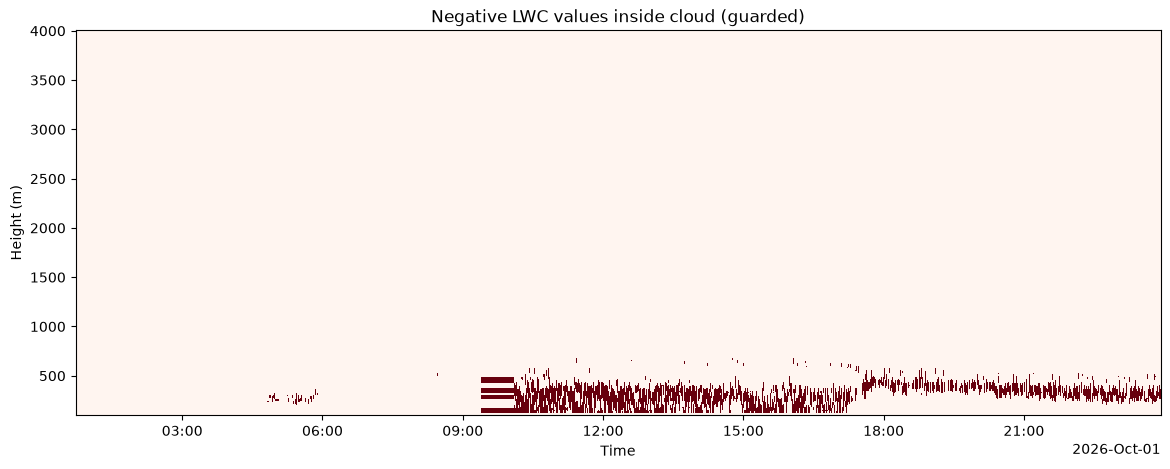

In [18]:
negative_lwc = (lwc_guarded < 0) & ds_retrieval["common_mask"]

plt.figure(figsize=(14, 5))
negative_lwc.astype(int).plot(x="Time", y="range", cmap="Reds", add_colorbar=False)
plt.title("Negative LWC values inside cloud (guarded)")
plt.xlabel("Time"); plt.ylabel("Height (m)")
plt.show()


 ### 4b. LWC map (main output)

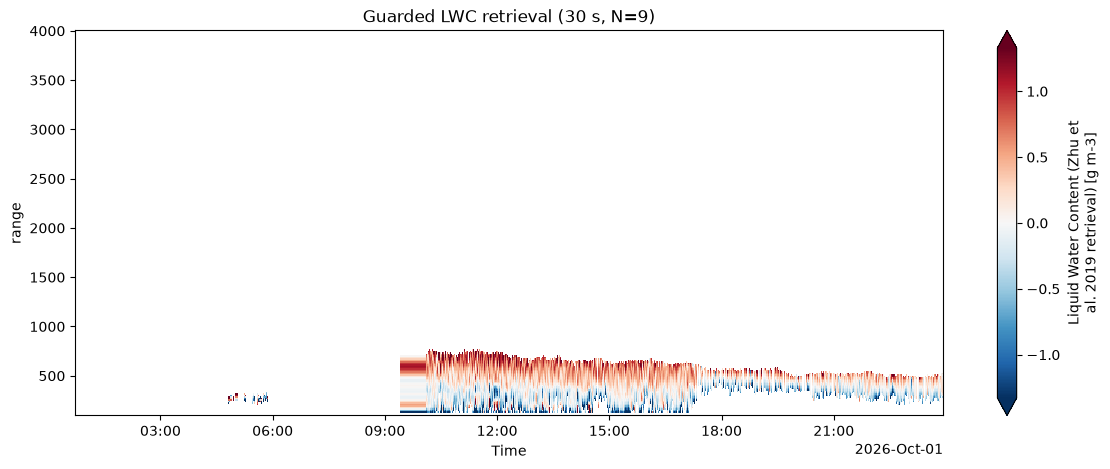

In [19]:
lwc_guarded.plot(
    x="Time", y="range", figsize=(14, 5), cmap="RdBu_r", robust=True,
)
plt.title("Guarded LWC retrieval (30 s, N=9)")
plt.show()


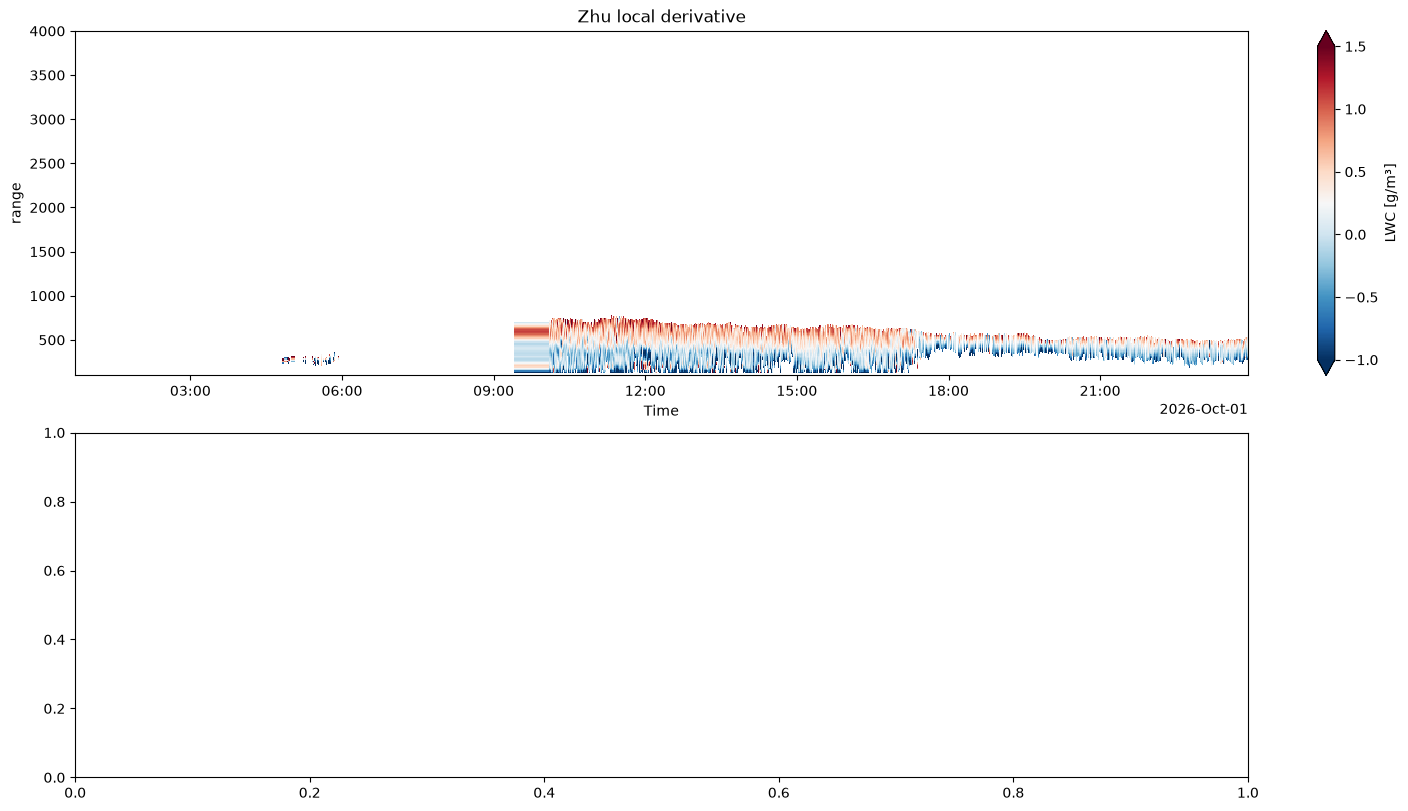

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
lwc_guarded.where(ds_retrieval["common_mask"]).plot(
    x="Time", y="range", ax=axes[0], vmin=-1, vmax=1.5, cmap="RdBu_r",
    cbar_kwargs={"label": "LWC [g/m³]"})
axes[0].set_title("Zhu local derivative")

plt.show()

 ### 4c. Two supporting graphs: LWC distribution + negative-gradient locations

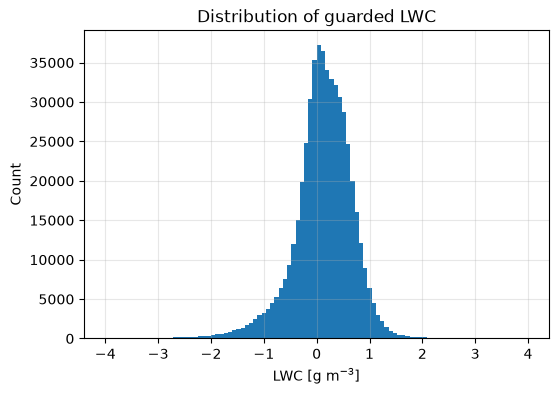

In [21]:
vals = lwc_guarded.where(ds_retrieval["common_mask"]).values
vals = vals[np.isfinite(vals)]

plt.figure(figsize=(6, 4))
plt.hist(vals, bins=100, range=(-4, 4))
plt.xlabel("LWC [g m$^{-3}$]")
plt.ylabel("Count")
plt.title("Distribution of guarded LWC")
plt.grid(alpha=0.3)
plt.show()


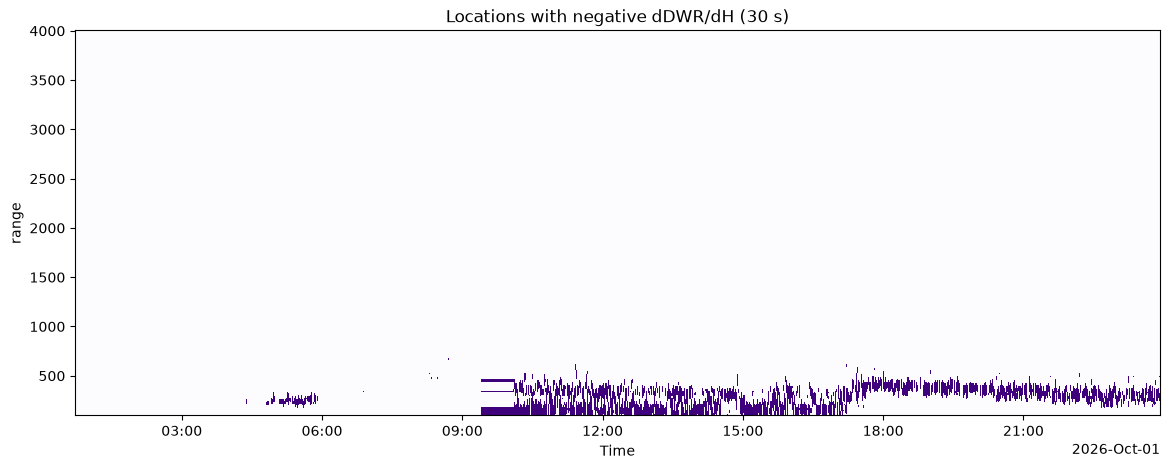

In [22]:
negative_grad = (ddwr_dh_smoothed < 0) & ds_retrieval["common_mask"]

plt.figure(figsize=(14, 5))
negative_grad.astype(int).plot(x="Time", y="range", cmap="Purples", add_colorbar=False)
plt.title("Locations with negative dDWR/dH (30 s)")
plt.show()


 ================================================================================================================================================================================================

 ## 5. LWP — kept only for later comparison (general chart, closure scatter, 3-profile spot check)

 ================================================================================================================================================================================================

 ### 5a. General LWP chart

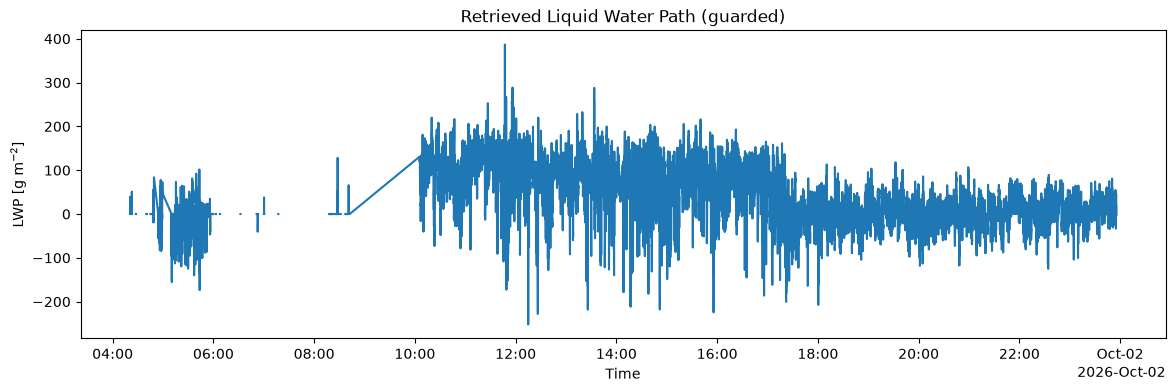

In [23]:
dz = xr.DataArray(np.gradient(dwr_2km_filt["range"].values),
                  dims="range", coords={"range": dwr_2km_filt["range"]})
lwp_guarded = (lwc_guarded.where(ds_retrieval["common_mask"]).fillna(0) * dz).sum(dim="range")
lwp_guarded = lwp_guarded.where(ds_retrieval["common_mask"].any(dim="range"))
lwp_guarded.attrs["units"] = "g m-2"

fig, ax = plt.subplots(figsize=(14, 4))
lwp_guarded.plot(ax=ax)
ax.set_title("Retrieved Liquid Water Path (guarded)")
ax.set_ylabel("LWP [g m$^{-2}$]")
ax.set_xlabel("Time")
plt.show()


 ### 5b. LWP closure test (scatter vs MWR)

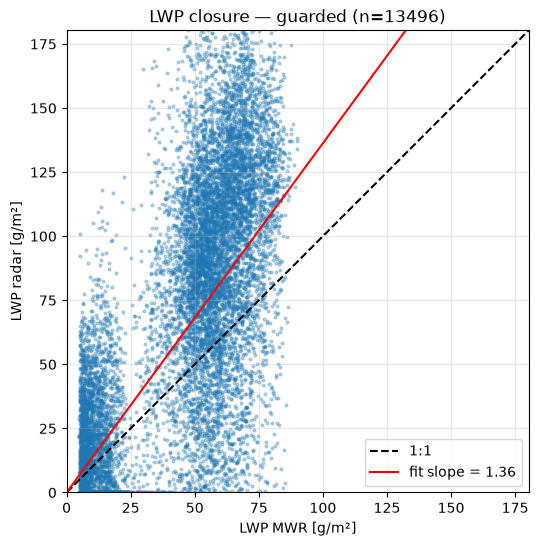

Slope through origin: 1.36   (want ~1.0)
Correlation:          0.60   (want > 0.7)
Bias:  radar - MWR = +13.2 g/m²


In [24]:
x = ds_retrieval["LWP"].values
y = lwp_guarded.values
good = np.isfinite(x) & np.isfinite(y) & (x > 5)   # ignore near-zero MWR

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x[good], y[good], s=4, alpha=0.3)
lim = max(np.nanpercentile(x[good], 99), np.nanpercentile(y[good], 99))
ax.plot([0, lim], [0, lim], "k--", label="1:1")
slope = np.nansum(x[good] * y[good]) / np.nansum(x[good] ** 2)
ax.plot([0, lim], [0, slope * lim], "r-", label=f"fit slope = {slope:.2f}")
ax.set_xlabel("LWP MWR [g/m²]"); ax.set_ylabel("LWP radar [g/m²]")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f"LWP closure — guarded (n={good.sum()})")
plt.show()

corr = np.corrcoef(x[good], y[good])[0, 1]
print(f"Slope through origin: {slope:.2f}   (want ~1.0)")
print(f"Correlation:          {corr:.2f}   (want > 0.7)")
print(f"Bias:  radar - MWR = {np.nanmean(y[good] - x[good]):+.1f} g/m²")


 ### 5c. Spot-check three profiles (kept for later comparison across methods)

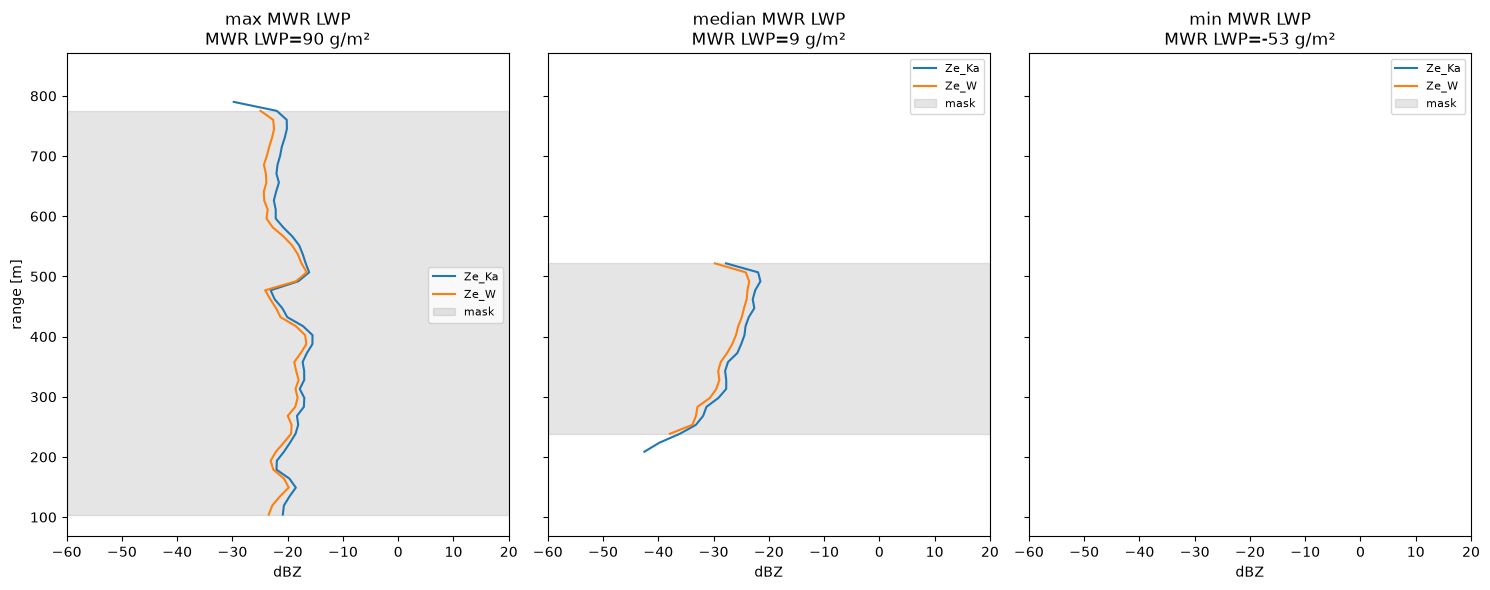

In [25]:
lwp_mwr_vals = ds_retrieval["LWP"].values
i_hi   = int(np.nanargmax(lwp_mwr_vals))
i_lo   = int(np.nanargmin(np.abs(lwp_mwr_vals - np.nanmedian(lwp_mwr_vals))))
i_zero = int(np.nanargmin(lwp_mwr_vals))

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
for ax, idx, label in zip(axes, [i_hi, i_lo, i_zero],
                          ["max MWR LWP", "median MWR LWP", "min MWR LWP"]):
    h = dwr_2km_smoothed["range"].values
    ax.plot(ds_retrieval["Ze_Ka"].sel(range=slice(0, 4000)).isel(Time=idx), h, label="Ze_Ka")
    ax.plot(ds_retrieval["Ze_W"].sel(range=slice(0, 4000)).isel(Time=idx),  h, label="Ze_W")
    mask_here = ds_retrieval["common_mask"].isel(Time=idx)
    ax.fill_betweenx(h, -60, 20, where=mask_here, color="grey", alpha=0.2, label="mask")
    ax.set_xlim(-60, 20); ax.set_xlabel("dBZ")
    ax.set_title(f"{label}\nMWR LWP={lwp_mwr_vals[idx]:.0f} g/m²")
    ax.legend(fontsize=8)
axes[0].set_ylabel("range [m]")
plt.tight_layout()
plt.show()


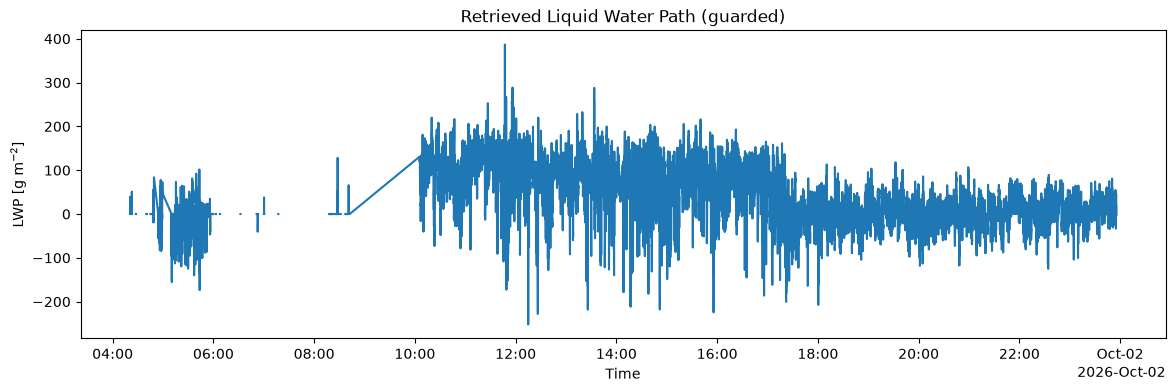

In [26]:
dz = xr.DataArray(np.gradient(dwr_2km_filt["range"].values),
                  dims="range", coords={"range": dwr_2km_filt["range"]})

retrieval_mask = ds_retrieval["common_mask"]

lwp_guarded = (
    lwc_guarded.where(retrieval_mask)
    .fillna(0)
    * dz
).sum(dim="range")

lwp_guarded = lwp_guarded.where(retrieval_mask.any(dim="range"))
lwp_guarded.attrs["units"] = "g m-2"

fig, ax = plt.subplots(figsize=(14, 4))
lwp_guarded.plot(ax=ax)
ax.set_title("Retrieved Liquid Water Path (guarded)")
ax.set_ylabel("LWP [g m$^{-2}$]")
ax.set_xlabel("Time")
plt.show()

In [27]:
dz = xr.DataArray(np.gradient(dwr_2km_filt["range"].values),
                  dims="range", coords={"range": dwr_2km_filt["range"]})
lwp_guarded_1500 = (lwc_guarded.where(ds_retrieval["common_mask"]).fillna(0) * dz).sum(dim="range")
lwp_guarded_1500 = lwp_guarded_1500.where(ds_retrieval["common_mask"].any(dim="range"))
lwp_guarded_1500.attrs["units"] = "g m-2"

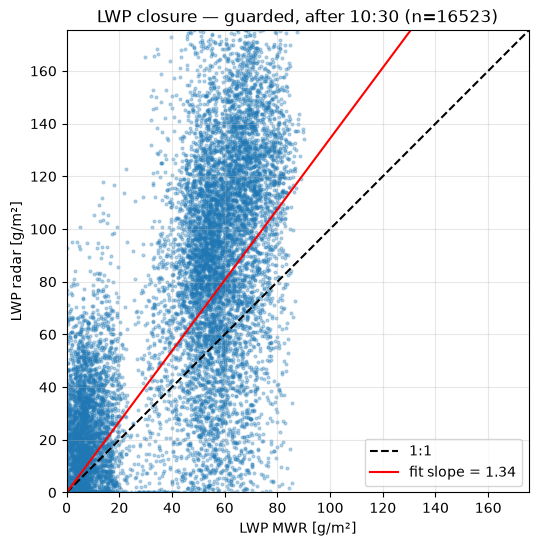

Slope through origin: 1.34   (want ~1.0)
Correlation:          0.66   (want > 0.7)
Bias:  radar - MWR = +10.2 g/m²


In [ ]:
t = pd.DatetimeIndex(ds_retrieval["Time"].values)                          # NEW
after = t.time >= pd.Timestamp("10:30").time()                             # NEW

x = ds_retrieval["LWP"].values
y = lwp_guarded_1500.values
good = after & np.isfinite(x) & np.isfinite(y)   # ignore near-zero MWR   # NEW: "after &"

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x[good], y[good], s=4, alpha=0.3)
lim = max(np.nanpercentile(x[good], 99), np.nanpercentile(y[good], 99))
ax.plot([0, lim], [0, lim], "k--", label="1:1")
slope = np.nansum(x[good] * y[good]) / np.nansum(x[good] ** 2)
ax.plot([0, lim], [0, slope * lim], "r-", label=f"fit slope = {slope:.2f}")
ax.set_xlabel("LWP MWR [g/m²]"); ax.set_ylabel("LWP radar [g/m²]")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f"LWP closure — guarded, after 10:30 (n={good.sum()})")   # NEW: "after 10:30"
plt.show()

corr = np.corrcoef(x[good], y[good])[0, 1]
print(f"Slope through origin: {slope:.2f}   (want ~1.0)")
print(f"Correlation:          {corr:.2f}   (want > 0.7)")
print(f"Bias:  radar - MWR = {np.nanmean(y[good] - x[good]):+.1f} g/m²")

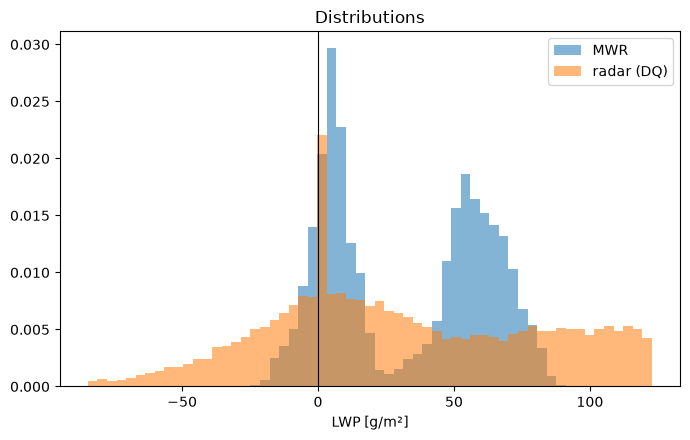

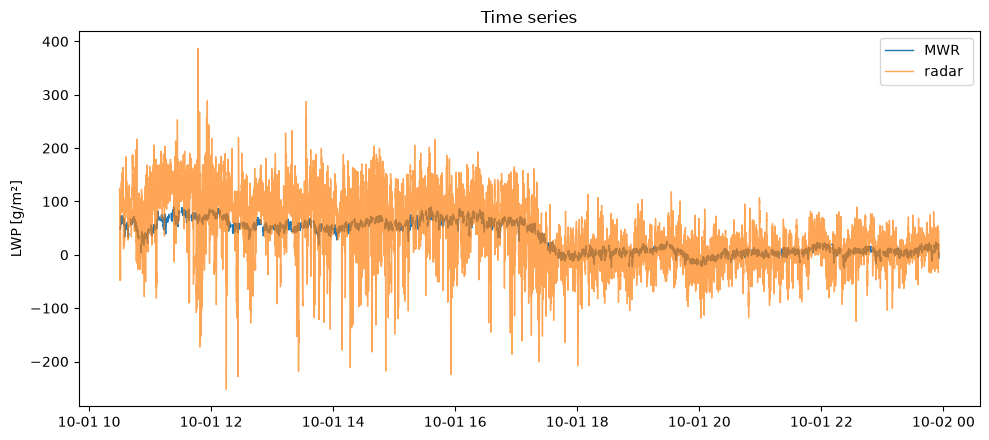

MWR   : mean   +32.7 std   29.1 p05    -6.1 p50   +36.3 p95   +74.9
radar : mean   +42.9 std   61.3 p05   -43.8 p50   +32.0 p95  +144.8


In [45]:
t = pd.DatetimeIndex(ds_retrieval["Time"].values)
after = t.time >= pd.Timestamp("10:30").time()

# %% Distribution comparison, not just scatter
x = ds_retrieval["LWP"].values
y = lwp_guarded_1500.values
good = np.isfinite(x) & np.isfinite(y) & after

bins = np.linspace(min(np.nanpercentile(y[good], 1), 0), np.nanpercentile(x[good], 99) * 1.5, 60)

# %% Plot 1: Verteilungen (Histogramm)
plt.figure(figsize=(7, 4.5))
plt.hist(x[good], bins=bins, alpha=0.55, label="MWR", density=True)
plt.hist(y[good], bins=bins, alpha=0.55, label="radar (DQ)", density=True)
plt.axvline(0, color="k", lw=0.8); plt.legend()
plt.xlabel("LWP [g/m²]"); plt.title("Distributions")
plt.tight_layout(); plt.show()

# %% Plot 2: Zeitreihe
plt.figure(figsize=(10, 4.5))
plt.plot(t[after], x[after], label="MWR", lw=1)                       # NEW: [after]
plt.plot(t[after], y[after], label="radar ", lw=1, alpha=0.7)         # NEW: [after]
plt.legend(); plt.ylabel("LWP [g/m²]"); plt.title("Time series")
plt.tight_layout(); plt.show()

# %% Statistik
for nm, v in [("MWR", x[good]), ("radar", y[good])]:
    print(f"{nm:6s}: mean {v.mean():+7.1f} std {v.std():6.1f} "
          f"p05 {np.percentile(v,5):+7.1f} p50 {np.percentile(v,50):+7.1f} p95 {np.percentile(v,95):+7.1f}")

2026-10-01T10:30 to 2026-10-01T23:00: 10777 profiles used


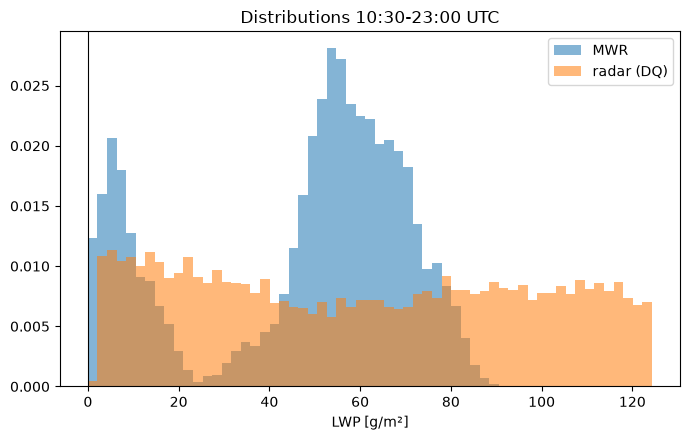

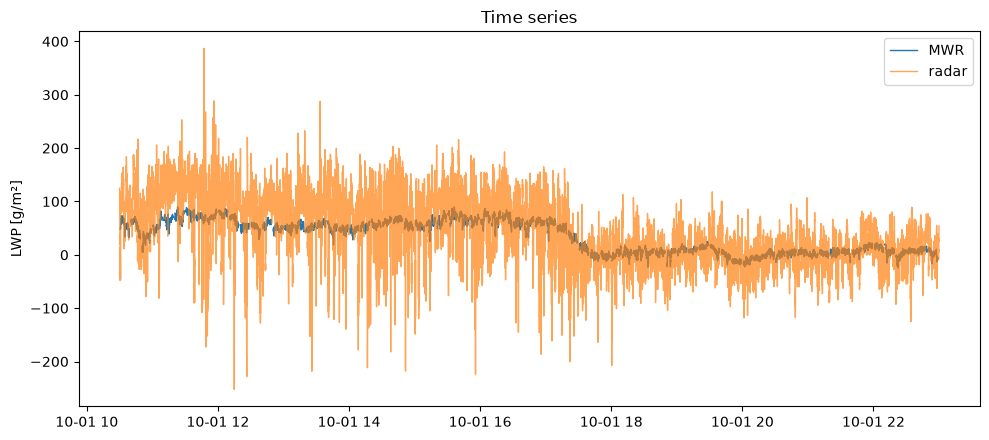

MWR   : mean   +43.7 std   26.7 p05    -1.5 p50   +53.0 p95   +77.2
radar : mean   +75.2 std   47.9 p05    +7.6 p50   +74.6 p95  +154.2


In [44]:
# %% Time window (Cloudnet times are UTC; Finland in October = UTC+3, so 09:00 UTC = 12:00 local)
day = str(ds_retrieval["Time"].values[0])[:10]                  # date of this dataset, e.g. "2026-10-01"
TIME_START = np.datetime64(f"{day}T10:30")
TIME_END   = np.datetime64(f"{day}T23:00")

time = ds_retrieval["Time"].values
in_window = (time >= TIME_START) & (time <= TIME_END)

# %% Distribution comparison, not just scatter
x = ds_retrieval["LWP"].values
y = lwp_guarded_1500.values
good = np.isfinite(x) & np.isfinite(y) & (y > 2) & in_window     # <- only the chosen hours
print(f"{TIME_START} to {TIME_END}: {good.sum()} profiles used")

bins = np.linspace(min(np.nanpercentile(y[good], 1), 0), np.nanpercentile(x[good], 99) * 1.5, 60)

# %% Plot 1: Verteilungen (Histogramm)
plt.figure(figsize=(7, 4.5))
plt.hist(x[good], bins=bins, alpha=0.55, label="MWR", density=True)
plt.hist(y[good], bins=bins, alpha=0.55, label="radar (DQ)", density=True)
plt.axvline(0, color="k", lw=0.8); plt.legend()
plt.xlabel("LWP [g/m²]"); plt.title(f"Distributions {str(TIME_START)[11:16]}-{str(TIME_END)[11:16]} UTC")
plt.tight_layout(); plt.show()

# %% Plot 2: Zeitreihe (only the window)
plt.figure(figsize=(10, 4.5))
plt.plot(time[in_window], x[in_window], label="MWR", lw=1)
plt.plot(time[in_window], y[in_window], label="radar", lw=1, alpha=0.7)
plt.legend(); plt.ylabel("LWP [g/m²]"); plt.title("Time series")
plt.tight_layout(); plt.show()

# %% Statistik
for nm, v in [("MWR", x[good]), ("radar", y[good])]:
    print(f"{nm:6s}: mean {v.mean():+7.1f} std {v.std():6.1f} "
          f"p05 {np.percentile(v,5):+7.1f} p50 {np.percentile(v,50):+7.1f} p95 {np.percentile(v,95):+7.1f}")

2026-10-01T09:00 to 2026-10-01T15:00: 5480 profiles used


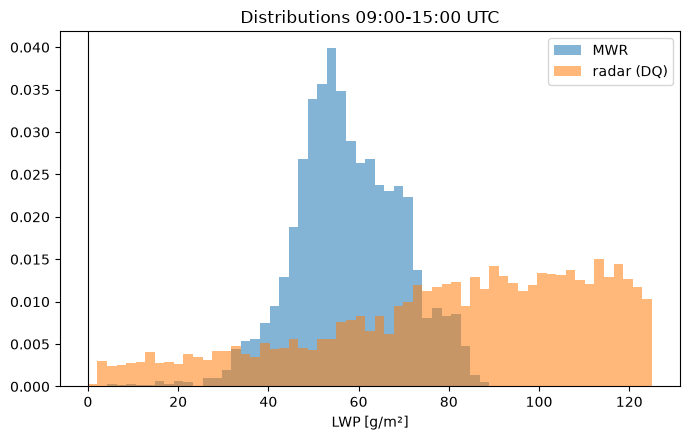

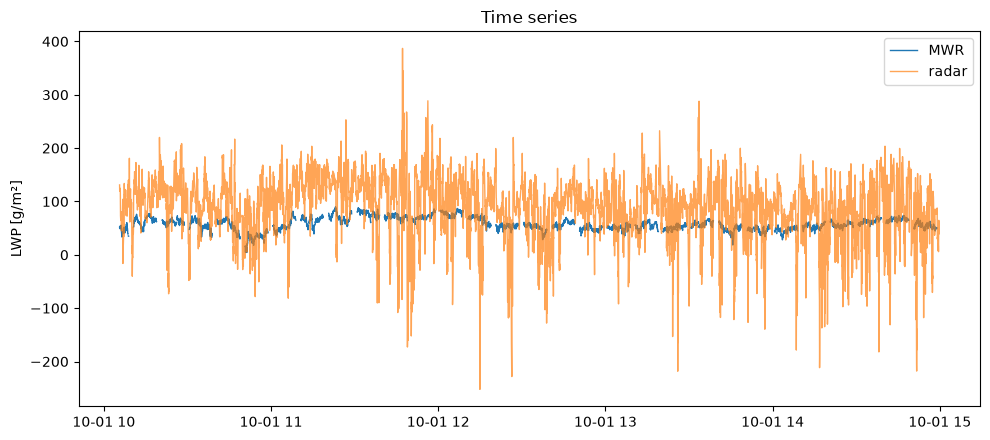

MWR   : mean   +57.7 std   12.0 p05   +38.5 p50   +56.8 p95   +78.4
radar : mean   +99.7 std   42.6 p05   +25.1 p50  +100.9 p95  +167.7


In [30]:
# %% Time window (Cloudnet times are UTC; Finland in October = UTC+3, so 09:00 UTC = 12:00 local)
day = str(ds_retrieval["Time"].values[0])[:10]                  # date of this dataset, e.g. "2026-10-01"
TIME_START = np.datetime64(f"{day}T09:00")
TIME_END   = np.datetime64(f"{day}T15:00")

time = ds_retrieval["Time"].values
in_window = (time >= TIME_START) & (time <= TIME_END)

# %% Distribution comparison, not just scatter
x = ds_retrieval["LWP"].values
y = lwp_guarded_1500.values
good = np.isfinite(x) & np.isfinite(y) & (y > 2) & in_window     # <- only the chosen hours
print(f"{TIME_START} to {TIME_END}: {good.sum()} profiles used")

bins = np.linspace(min(np.nanpercentile(y[good], 1), 0), np.nanpercentile(x[good], 99) * 1.5, 60)

# %% Plot 1: Verteilungen (Histogramm)
plt.figure(figsize=(7, 4.5))
plt.hist(x[good], bins=bins, alpha=0.55, label="MWR", density=True)
plt.hist(y[good], bins=bins, alpha=0.55, label="radar (DQ)", density=True)
plt.axvline(0, color="k", lw=0.8); plt.legend()
plt.xlabel("LWP [g/m²]"); plt.title(f"Distributions {str(TIME_START)[11:16]}-{str(TIME_END)[11:16]} UTC")
plt.tight_layout(); plt.show()

# %% Plot 2: Zeitreihe (only the window)
plt.figure(figsize=(10, 4.5))
plt.plot(time[in_window], x[in_window], label="MWR", lw=1)
plt.plot(time[in_window], y[in_window], label="radar", lw=1, alpha=0.7)
plt.legend(); plt.ylabel("LWP [g/m²]"); plt.title("Time series")
plt.tight_layout(); plt.show()

# %% Statistik
for nm, v in [("MWR", x[good]), ("radar", y[good])]:
    print(f"{nm:6s}: mean {v.mean():+7.1f} std {v.std():6.1f} "
          f"p05 {np.percentile(v,5):+7.1f} p50 {np.percentile(v,50):+7.1f} p95 {np.percentile(v,95):+7.1f}")

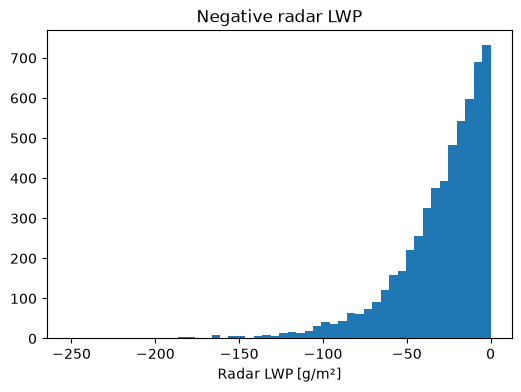

In [31]:
plt.figure(figsize=(6,4))
plt.hist(y[(y < 0) & np.isfinite(y)], bins=50)
plt.xlabel("Radar LWP [g/m²]")
plt.title("Negative radar LWP")
plt.show()

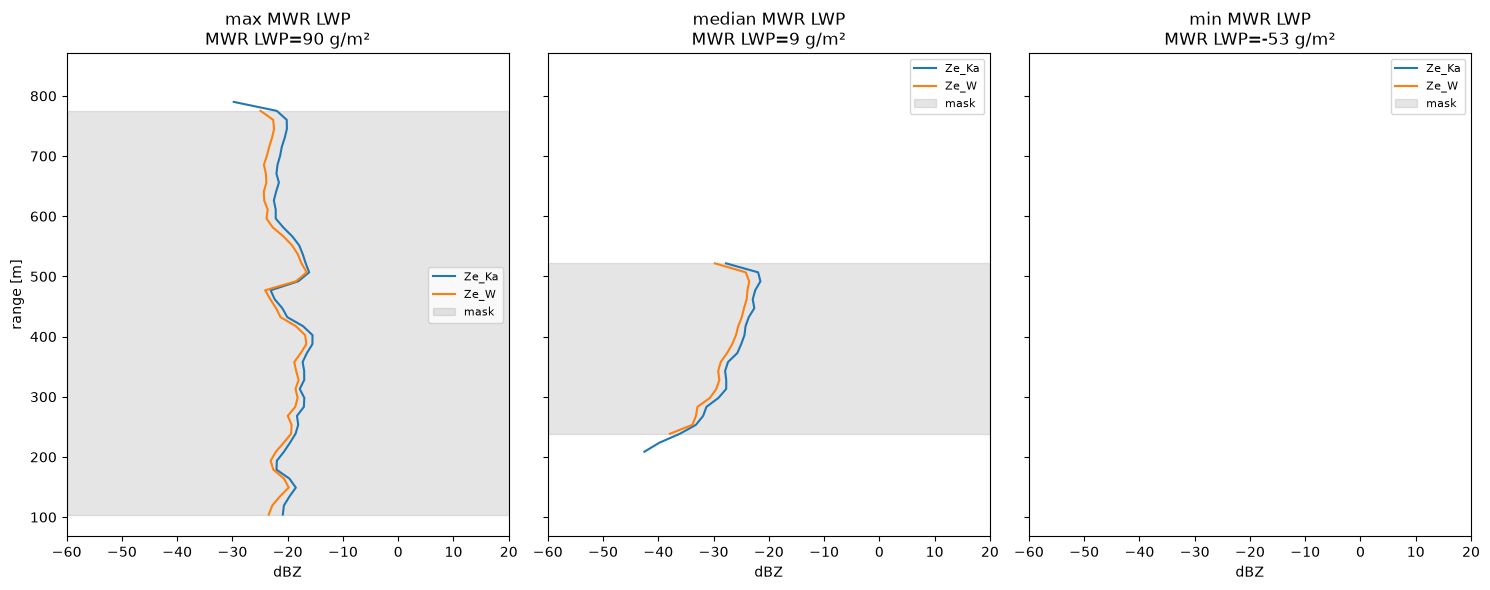

In [32]:
retrieval_mask = ds_retrieval["common_mask"] 

lwp_mwr_vals = ds_retrieval["LWP"].values
i_hi   = int(np.nanargmax(lwp_mwr_vals))
i_lo   = int(np.nanargmin(np.abs(lwp_mwr_vals - np.nanmedian(lwp_mwr_vals))))
i_zero = int(np.nanargmin(lwp_mwr_vals))

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)

for ax, idx, label in zip(
    axes,
    [i_hi, i_lo, i_zero],
    ["max MWR LWP", "median MWR LWP", "min MWR LWP"],
):
    h = dwr_2km_smoothed["range"].values

    ax.plot(ds_retrieval["Ze_Ka"].sel(range=slice(0, 4000)).isel(Time=idx), h, label="Ze_Ka")
    ax.plot(ds_retrieval["Ze_W"].sel(range=slice(0, 4000)).isel(Time=idx), h, label="Ze_W")

    mask_here = retrieval_mask.isel(Time=idx)

    ax.fill_betweenx(
        h, -60, 20,
        where=mask_here,
        color="grey",
        alpha=0.2,
        label="mask"
    )

    ax.set_xlim(-60, 20)
    ax.set_xlabel("dBZ")
    ax.set_title(f"{label}\nMWR LWP={lwp_mwr_vals[idx]:.0f} g/m²")
    ax.legend(fontsize=8)

axes[0].set_ylabel("range [m]")
plt.tight_layout()
plt.show()

In [33]:
# %% Export Zhu retrieval outputs for notebook 06
from pathlib import Path
import xarray as xr

ds_output_zhu = xr.Dataset(
    {
        "lwc_guarded":  lwc_guarded.rename("lwc_guarded"),
        "n_windows":    n_windows.rename("n_windows"),
        "dwr_filtered": dwr_2km_filt.rename("dwr_filtered"),
        "m_eff": m_eff.rename("m_eff"),
        "derivative_guarded": derivative_guarded.rename("derivative_guarded"),
        "n_used": n_used.rename("n_used")
        
    },
    attrs={
        "description": "Zhu et al. (2019) guarded retrieval output",
        "N_default": 13,                    # was 9
        "max_ddwr_dh": 30.0,                # add
        "max_window_std": 1.0,              # add
        "edge_pad_bottom": 2,               # add
        "edge_pad_top": 1,                  # add
        "input_dwr": "30 s averaged, 1 dB despiked",
        "mask_used": "common_mask",
        "created_by": "04_zhu_guarded_retrieval_CLEANED.ipynb",
    },
)

out_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_output_zhu.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)
ds_output_zhu.to_netcdf(out_path)
print(f"Saved → {out_path}")

Saved → ..\data\processed\20261001_pallas_interpolation_CLARA\retrieval_output_zhu.nc


## Comparison of different number of Gates N

In [46]:
# =====================================================================
# WINDOW-SIZE SWEEP — two rounds: no padding, and (bottom=2, top=1)
# =====================================================================
N_VALUES = [5, 7, 9, 11, 13, 17, 21]
PAD_SETS = [(0, 0), (2, 1)]
MAX_DDWR = 30.0
SIG_DWR_DB = 0.223          # interior per-gate DWR noise

# The window std is signal + noise in quadrature. The signal part grows with
# the window span (so with N), the noise part doesn't. Scale accordingly,
# calibrated so threshold(N=13) = 1.0 dB, i.e. your production value.
K_SIGNAL = np.sqrt(max(1.0**2 - SIG_DWR_DB**2, 0.0)) / 13.0

STD_MODE = "scaled"         # "scaled" | "fixed" (1.0 for all N) | "off"

def std_threshold(N):
    if STD_MODE == "off":   return 1e9
    if STD_MODE == "fixed": return 1.0
    return float(np.sqrt((K_SIGNAL * N) ** 2 + SIG_DWR_DB ** 2))

cmask = ds_retrieval["common_mask"].transpose("Time", "range")
dz    = np.gradient(dwr_2km_filt["range"].values)
dr_m  = float(np.median(np.diff(dwr_2km_filt["range"].values)))
dk    = float((ds_retrieval["kappa_W"] - ds_retrieval["kappa_Ka"])
              .where(cmask).median())

assert dwr_2km_filt.transpose("Time", "range").shape == cmask.shape, \
    "dwr_2km_filt is not on the mask grid - restart the kernel"

print(f"gate {dr_m:.1f} m | dkappa {dk:.2f} dB/km/(g/m3) | std mode '{STD_MODE}'")

sweep_N = {}
for pb, pt in PAD_SETS:
    for N in N_VALUES:
        thr = std_threshold(N)
        lwc, *_ = retrieve_lwc_zhu(
            dwr=dwr_2km_filt,
            kappa_w=ds_retrieval["kappa_W"],
            kappa_ka=ds_retrieval["kappa_Ka"],
            alpha_w=ds_retrieval["alpha_W"],
            alpha_ka=ds_retrieval["alpha_Ka"],
            cloud_mask=cmask,
            N_default=N, min_cloud_gates=3,
            max_ddwr_dh=MAX_DDWR, max_window_std=thr,
            edge_pad_bottom=pb, edge_pad_top=pt,
        )
        sweep_N[(pb, pt, N)] = lwc
        print(f"  pad ({pb},{pt})  N={N:>2}  span={N*dr_m:>4.0f} m  "
              f"std_thr={thr:.2f} dB  {int(np.isfinite(lwc.values).sum()):>7} gates")

gate 13.5 m | dkappa 3.63 dB/km/(g/m3) | std mode 'scaled'
  pad (0,0)  N= 5  span=  68 m  std_thr=0.44 dB   581523 gates
  pad (0,0)  N= 7  span=  95 m  std_thr=0.57 dB   586794 gates
  pad (0,0)  N= 9  span= 122 m  std_thr=0.71 dB   589015 gates
  pad (0,0)  N=11  span= 149 m  std_thr=0.85 dB   589892 gates
  pad (0,0)  N=13  span= 176 m  std_thr=1.00 dB   589528 gates
  pad (0,0)  N=17  span= 230 m  std_thr=1.29 dB   579880 gates
  pad (0,0)  N=21  span= 284 m  std_thr=1.59 dB   573321 gates
  pad (2,1)  N= 5  span=  68 m  std_thr=0.44 dB   536329 gates
  pad (2,1)  N= 7  span=  95 m  std_thr=0.57 dB   537349 gates
  pad (2,1)  N= 9  span= 122 m  std_thr=0.71 dB   536884 gates
  pad (2,1)  N=11  span= 149 m  std_thr=0.85 dB   534710 gates
  pad (2,1)  N=13  span= 176 m  std_thr=1.00 dB   532087 gates
  pad (2,1)  N=17  span= 230 m  std_thr=1.29 dB   524700 gates
  pad (2,1)  N=21  span= 284 m  std_thr=1.59 dB   521836 gates


In [47]:
# --- compare ---
lwp_mwr = ds_retrieval["LWP"].values

def sigma_lwc_ols(N, sig_dwr, dr_m, dkappa):
    """OLS slope error through the retrieval equation. White-noise prediction."""
    if N < 3:
        return np.nan
    slope = sig_dwr * np.sqrt(12.0 / (N * (N**2 - 1))) / dr_m * 1000.0   # dB/km
    return 0.5 * slope / dkappa

def diagnose_N(pb, pt):
    print(f"\n=== edge pads (bottom={pb}, top={pt}) ===")
    print(f"{'N':>4}{'span':>6}{'gates':>9}{'prof':>7}{'median':>8}{'std':>7}"
          f"{'pred':>7}{'ratio':>7}{'<0':>6}{'<-1':>7}{'<-2':>7}"
          f" | {'LWPbias%':>9}{'rmse':>7}{'corr':>6}")
    for N in N_VALUES:
        L = sweep_N[(pb, pt, N)].where(cmask).values
        v = L[np.isfinite(L)]
        if v.size < 100:
            print(f"{N:>4}   too few gates ({v.size})")
            continue

        lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0) * dz, axis=1)
        lwp_r[~np.isfinite(L).any(axis=1)] = np.nan
        ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 20)

        if ok.sum() >= 30:
            bias = np.median(100 * (lwp_r[ok] - lwp_mwr[ok]) / lwp_mwr[ok])
            rmse = np.sqrt(np.mean((lwp_r[ok] - lwp_mwr[ok]) ** 2))
            corr = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1]
        else:
            bias = rmse = corr = np.nan

        pred  = sigma_lwc_ols(N, SIG_DWR_DB, dr_m, dk)
        nprof = int(np.isfinite(L).any(axis=1).sum())

        print(f"{N:>4}{N*dr_m:>6.0f}{v.size:>9}{nprof:>7}{np.median(v):>8.3f}"
              f"{v.std():>7.3f}{pred:>7.3f}{v.std()/pred:>7.2f}"
              f"{(v < 0).mean():>6.0%}{(v < -1).mean():>7.1%}{(v < -2).mean():>7.1%}"
              f" | {bias:>9.1f}{rmse:>7.1f}{corr:>6.2f}")

for pb, pt in PAD_SETS:
    diagnose_N(pb, pt)


=== edge pads (bottom=0, top=0) ===
   N  span    gates   prof  median    std   pred  ratio    <0    <-1    <-2 |  LWPbias%   rmse  corr
   5    68   581523  22280   0.180  1.004  0.719   1.40   41%  10.5%   3.5% |      55.2   80.0  0.27
   7    95   586794  22157   0.181  0.917  0.430   2.13   39%   9.1%   3.3% |      31.2   73.4  0.26
   9   122   589015  22005   0.174  0.860  0.294   2.93   38%   8.6%   3.2% |       7.7   67.6  0.25
  11   149   589892  21745   0.162  0.824  0.217   3.80   38%   8.4%   3.1% |     -18.5   68.8  0.21
  13   176   589528  21395   0.146  0.801  0.169   4.75   39%   8.4%   3.0% |     -50.8   71.0  0.19
  17   230   579880  20595   0.120  0.717  0.113   6.37   41%   7.6%   1.9% |     -28.5   67.3  0.23
  21   284   573321  20179   0.112  0.681  0.082   8.31   43%   7.0%   1.1% |      -9.9   69.2  0.27

=== edge pads (bottom=2, top=1) ===
   N  span    gates   prof  median    std   pred  ratio    <0    <-1    <-2 |  LWPbias%   rmse  corr
   5    68   5363

## Test the edge pads

In [48]:
# --- pad sweep ---
PADS      = [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2)]
N_DEFAULT = 13
cmask     = ds_retrieval["common_mask"].transpose("Time", "range")

assert dwr_2km_filt.transpose("Time", "range").shape == cmask.shape, \
    "dwr_2km_filt is not on the mask grid - a later cell overwrote it; restart the kernel"

sweep_pad = {}
for pb, pt in PADS:
    lwc, *_ = retrieve_lwc_zhu(
        dwr=dwr_2km_filt,
        kappa_w=ds_retrieval["kappa_W"],
        kappa_ka=ds_retrieval["kappa_Ka"],
        alpha_w=ds_retrieval["alpha_W"],
        alpha_ka=ds_retrieval["alpha_Ka"],
        cloud_mask=cmask,
        N_default=N_DEFAULT, min_cloud_gates=3,
        max_ddwr_dh=20.0, max_window_std=1.0,
        edge_pad_bottom=pb, edge_pad_top=pt,
    )
    sweep_pad[(pb, pt)] = lwc
    print(f"  pad ({pb},{pt}): {int(np.isfinite(lwc.values).sum())} gates")

  pad (0,0): 580521 gates
  pad (1,0): 568527 gates
  pad (2,0): 552253 gates
  pad (2,1): 530136 gates
  pad (2,2): 507030 gates


In [49]:
# --- compare ---
dz       = np.gradient(dwr_2km_filt["range"].values)
lwp_mwr  = ds_retrieval["LWP"].values

base     = sweep_pad[PADS[0]].where(cmask).values
base_n   = max(int(np.isfinite(base).sum()), 1)
base_lwp = np.nansum(np.where(np.isfinite(base), base, 0.0) * dz, axis=1)
base_lwp[~np.isfinite(base).any(axis=1)] = np.nan

print(f"{'pad(b,t)':>9}{'gates':>9}{'keep%':>7}{'median':>8}{'std':>7}{'<0':>6}"
      f" | {'LWPbias%':>9}{'LWPrmse':>9}{'corr':>6}{'vs(0,0)%':>10}")
for k in PADS:
    L = sweep_pad[k].where(cmask).values
    v = L[np.isfinite(L)]
    lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0) * dz, axis=1)
    lwp_r[~np.isfinite(L).any(axis=1)] = np.nan

    ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 20)
    if v.size == 0 or ok.sum() < 30:
        print(f"{str(k):>9}  too few valid gates/profiles - skipped")
        continue

    bias = np.median(100*(lwp_r[ok] - lwp_mwr[ok]) / lwp_mwr[ok])
    rmse = np.sqrt(np.mean((lwp_r[ok] - lwp_mwr[ok])**2))
    corr = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1]
    ok2  = ok & np.isfinite(base_lwp) & (base_lwp > 0)
    rel  = np.median(100*(lwp_r[ok2] - base_lwp[ok2]) / base_lwp[ok2])

    print(f"{str(k):>9}{v.size:>9}{100*v.size/base_n:>7.1f}{np.median(v):>8.3f}"
          f"{v.std():>7.3f}{(v < 0).mean():>6.0%} | {bias:>9.1f}{rmse:>9.1f}"
          f"{corr:>6.2f}{rel:>10.1f}")

 pad(b,t)    gates  keep%  median    std    <0 |  LWPbias%  LWPrmse  corr  vs(0,0)%
   (0, 0)   580521  100.0   0.146  0.662   39% |      35.9     59.7  0.33       0.0
   (1, 0)   568527   97.9   0.160  0.632   37% |      44.7     59.3  0.35       0.0
   (2, 0)   552253   95.1   0.181  0.569   35% |      96.3     72.4  0.39      38.9
   (2, 1)   530136   91.3   0.150  0.533   37% |      60.2     57.5  0.39      10.6
   (2, 2)   507030   87.3   0.128  0.529   39% |      38.3     52.2  0.37      -5.8


In [ ]:
mask = ds_retrieval["common_mask"].transpose("Time", "range").values.astype(bool)

In [ ]:
def sigma_dwr(dwr_block, mask_block):
    """sigma_DWR from adjacent-gate differences, per-profile trend removed."""
    x = np.asarray(dwr_block, float).copy()
    x[~np.asarray(mask_block, bool)] = np.nan
    k = np.arange(x.shape[1], dtype=float)
    for t in range(x.shape[0]):
        g = np.isfinite(x[t])
        if g.sum() >= 3:
            x[t, g] -= np.polyval(np.polyfit(k[g], x[t, g], 1), k[g])
    d = np.diff(x, axis=1).ravel()
    d = d[np.isfinite(d)]
    return (np.sqrt(np.var(d, ddof=1)/2), d.size) if d.size > 30 else (np.nan, 0)


# mean cloud height per profile
r = ds_retrieval["range"].values
h_mid = np.array([r[np.flatnonzero(m)].max() if m.sum() >= 3 else np.nan
                  for m in mask])

edges = np.nanpercentile(h_mid, [0, 20, 40, 60, 80, 100])
centres, sigmas = [], []
for i in range(len(edges)-1):
    sel = (h_mid >= edges[i]) & (h_mid < edges[i+1])
    if sel.sum() < 30:
        continue
    s, n = sigma_dwr(dwr_2km_filt[sel], mask[sel])
    centres.append(np.nanmean(h_mid[sel])); sigmas.append(s)
    print(f"  h ~ {centres[-1]:6.0f} m : sigma {s:.3f} dB "
          f"({sel.sum()} profiles, {n} pairs)")

centres, sigmas = np.array(centres), np.array(sigmas)
if len(centres) >= 3:
    a, b = np.polyfit(1/centres, sigmas, 1)
    print(f"\nfit sigma = a/h + b  ->  a = {a:.0f} dB*m, b = {b:.3f} dB")
    print(f"predicted sigma at 750 m: {a/750+b:.3f}, "
          f"at 1400 m: {a/1400+b:.3f} dB")

  h ~    428 m : sigma 0.164 dB (3510 profiles, 44542 pairs)
  h ~    533 m : sigma 0.135 dB (4762 profiles, 80884 pairs)
  h ~    587 m : sigma 0.331 dB (4134 profiles, 85187 pairs)
  h ~    657 m : sigma 0.397 dB (4550 profiles, 165273 pairs)
  h ~    723 m : sigma 0.284 dB (5593 profiles, 228289 pairs)

fit sigma = a/h + b  ->  a = -212 dB*m, b = 0.636 dB
predicted sigma at 750 m: 0.354, at 1400 m: 0.485 dB


In [ ]:
def sigma_dwr(dwr_block, mask_block):
    """sigma_DWR from adjacent-gate differences, per-profile trend removed."""
    x = np.asarray(dwr_block, float).copy()
    x[~np.asarray(mask_block, bool)] = np.nan
    k = np.arange(x.shape[1], dtype=float)
    for t in range(x.shape[0]):
        g = np.isfinite(x[t])
        if g.sum() >= 3:
            x[t, g] -= np.polyval(np.polyfit(k[g], x[t, g], 1), k[g])
    d = np.diff(x, axis=1).ravel()
    d = d[np.isfinite(d)]
    return (np.sqrt(np.var(d, ddof=1)/2), d.size) if d.size > 30 else (np.nan, 0)

height_mask = (r >= 1) & (r <= 10000)
dwr_2km_filt = dwr_2km_filt[:, height_mask]
mask = mask[:, height_mask]
r = r[height_mask]

# mean cloud height per profile
r = ds_retrieval["range"].values
h_mid = np.array([r[np.flatnonzero(m)].mean() if m.sum() >= 3 else np.nan
                  for m in mask])

edges = np.nanpercentile(h_mid, [0, 20, 40, 60, 80, 100])
centres, sigmas = [], []
for i in range(len(edges)-1):
    sel = (h_mid >= edges[i]) & (h_mid < edges[i+1])
    if sel.sum() < 30:
        continue
    s, n = sigma_dwr(dwr_2km_filt[sel], mask[sel])
    centres.append(np.nanmean(h_mid[sel])); sigmas.append(s)
    print(f"  h ~ {centres[-1]:6.0f} m : sigma {s:.3f} dB "
          f"({sel.sum()} profiles, {n} pairs)")

centres, sigmas = np.array(centres), np.array(sigmas)
if len(centres) >= 3:
    a, b = np.polyfit(1/centres, sigmas, 1)
    print(f"\nfit sigma = a/h + b  ->  a = {a:.0f} dB*m, b = {b:.3f} dB")
    print(f"predicted sigma at 750 m: {a/750+b:.3f}, "
          f"at 1400 m: {a/1400+b:.3f} dB")

  h ~    326 m : sigma 0.326 dB (3861 profiles, 69394 pairs)
  h ~    379 m : sigma 0.333 dB (4088 profiles, 124862 pairs)
  h ~    395 m : sigma 0.384 dB (5543 profiles, 176035 pairs)
  h ~    419 m : sigma 0.233 dB (4340 profiles, 127402 pairs)
  h ~    453 m : sigma 0.152 dB (4725 profiles, 106890 pairs)

fit sigma = a/h + b  ->  a = 187 dB*m, b = -0.194 dB
predicted sigma at 750 m: 0.055, at 1400 m: -0.061 dB


In [ ]:
# DWR residual after removing a smooth per-profile fit = what the retrieval calls noise
resid = np.full_like(dwr_2km_filt, np.nan)
kk = np.arange(dwr_2km_filt.shape[1], dtype=float)
for t in range(dwr_2km_filt.shape[0]):
    g = mask[t] & np.isfinite(dwr_2km_filt[t])
    if g.sum() >= 4:
        resid[t, g] = dwr_2km_filt[t, g] - np.polyval(np.polyfit(kk[g], dwr_2km_filt[t, g], 2), kk[g])

# local temporal Ze variability = proxy for small-scale spatial variability
ze = np.where(mask, ds_retrieval["Ze_W"], np.nan)
W = 5   # profiles, ~ a few seconds
loc_var = np.full_like(ze, np.nan)
for t in range(W, ze.shape[0] - W):
    loc_var[t] = np.nanstd(ze[t-W:t+W+1], axis=0)

a, b = np.abs(resid).ravel(), loc_var.ravel()
g = np.isfinite(a) & np.isfinite(b)
print(f"corr(|DWR residual|, local Ze variability) = "
      f"{np.corrcoef(a[g], b[g])[0,1]:+.3f}   (n={g.sum()})")

c:\Users\geron\miniforge3\envs\radar_lwc\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


corr(|DWR residual|, local Ze variability) = +0.131   (n=629750)


In [ ]:
import xarray as xr
import glob
W_FILE     = "../data/raw/pallas/20261001_pallasjarvi_rpg-fmcw-94_delft.nc"
TO_OLD_NAMES = {"lwp": "LWP", "air_pressure": "SurfPres", "radar_frequency": "Freq",
                "integration_time": "SeqIntTime", "number_of_averaged_chirps": "AvgNum",
                "number_of_spectral_samples": "DoppLen"}
def load_cloudnet(path):
    ds = xr.open_dataset(path)
    ds = ds.rename({"time": "Time"})
    ds = ds.assign_coords(Time=ds.Time.values.astype("datetime64[ns]"))
    ds = drop_duplicate_times(ds)
    ds = ds.rename({k: v for k, v in TO_OLD_NAMES.items() if k in ds})
    # back to the units your pipeline expects (CloudnetPy rpg.py convert_units, read backwards)
    if "LWP" in ds:
        ds["LWP"] = ds["LWP"] * 1000.0;        ds["LWP"].attrs["units"] = "g m-2"   # kg m-2 -> g m-2
    if "SurfPres" in ds:
        ds["SurfPres"] = ds["SurfPres"] / 100.0; ds["SurfPres"].attrs["units"] = "hPa"   # Pa -> hPa
    return ds

raw = load_cloudnet(W_FILE)



In [ ]:
print(raw["SurfWS"])

KeyError: "No variable named 'SurfWS'. Variables on the dataset include ['file_code', 'program_number', 'model_number', 'Freq', 'antenna_separation', ..., 'altitude', 'zenith_angle', 'height', 'range', 'Time']"

In [ ]:
wind_speed = raw["SurfWS"].values

In [ ]:
# advection speed proxy: horizontal wind from sounding, or the Doppler
# spectrum-width / mean-velocity variability. Bin sigma_DWR by it.
for lo, hi in [(0,3), (3,6), (6,10), (10,20)]:
    sel = mask & (wind_speed[:,None] >= lo) & (wind_speed[:,None] < hi)
    s, n = sigma_dwr(dwr_2km_filt[sel], mask[sel])
    print(f"U {lo:2d}-{hi:2d} m/s : sigma {s:.3f} dB  (n={n})")

U  0- 3 m/s : sigma 0.305 dB (profiles=1036, pairs=444)
U  3- 6 m/s : sigma 0.305 dB (profiles=4608, pairs=7038)
U  6-10 m/s : sigma 0.302 dB (profiles=6975, pairs=22235)
U 10-20 m/s : sigma 0.297 dB (profiles=2296, pairs=10752)


In [ ]:
d = np.diff(np.where(mask, dwr_2km_filt, np.nan), axis=1)

edge, interior = [], []
for t in range(mask.shape[0]):
    idx = np.flatnonzero(mask[t])
    if idx.size < 6:
        continue
    lo, hi = idx[0], idx[-1]
    for k in range(lo, hi):                      # k indexes the pair (k, k+1)
        if not np.isfinite(d[t, k]):
            continue
        (edge if (k == lo or k == hi - 1) else interior).append(d[t, k])

e, i = np.array(edge), np.array(interior)
f = e.std() / i.std()
print(f"edge pairs     n={e.size:6d}  std(delta)={e.std():.3f}")
print(f"interior pairs n={i.size:6d}  std(delta)={i.std():.3f}")
print(f"f = {f:.2f}   ->  {'DROP the edge gates' if f > 1.8 else 'KEEP them'}")

ValueError: operands could not be broadcast together with shapes (14915,45) (14915,127) () 

In [ ]:
import numpy as np, xarray as xr

# dwr_2km_filt is the reference grid; everything else gets reindexed onto it.
# reindex_like matches on LABELS (Time and range values), not position.
TR      = lambda a: a.transpose("Time", "range")
target  = TR(dwr_2km_filt)
to_grid = lambda a: TR(a).reindex_like(target)

mask45 = to_grid(ds_retrieval["common_mask"]).fillna(False).astype(bool)

print(f"grid: {target.shape[0]} profiles x {target.shape[1]} gates, "
      f"{target['range'].values[0]:.0f}-{target['range'].values[-1]:.0f} m")
print(f"gate spacing: {np.median(np.diff(target['range'].values)):.1f} m")
print(f"cloudy gates: {int(mask45.sum())}")

runs = {}
for pad in (0, 1):
    lwc, ddwr, meff, nwin, nused = retrieve_lwc_zhu(
        dwr        = target,
        kappa_w    = to_grid(ds_retrieval["kappa_W"]),
        kappa_ka   = to_grid(ds_retrieval["kappa_Ka"]),
        alpha_w    = to_grid(ds_retrieval["alpha_W"]),
        alpha_ka   = to_grid(ds_retrieval["alpha_Ka"]),
        cloud_mask = mask45,
        N_default  = 9,
        edge_pad   = pad,
    )
    ds_out = xr.Dataset(
        {"lwc_guarded": lwc, "dDWR_dh": ddwr, "m_eff": meff,
         "n_windows": nwin, "N_used": nused, "dwr_filtered": target,
         "common_mask": mask45},
        attrs={"edge_pad": pad, "N_default": 9})
    ds_out.to_netcdf(f"../data/processed/{Processed_Dataset}/retrieval_output_zhu_pad{pad}.nc")
    runs[pad] = ds_out
    print(f"edge_pad={pad}: {int(np.isfinite(lwc.values).sum())} gates retrieved")

grid: 30216 profiles x 86 gates, 701-1890 m
gate spacing: 13.5 m
cloudy gates: 14139
edge_pad=0: 11577 gates retrieved
edge_pad=1: 3608 gates retrieved


In [ ]:
m  = mask45.values
r  = target["range"].values
dr = float(np.median(np.diff(r)))
L  = {p: runs[p]["lwc_guarded"].values for p in (0, 1)}

T = np.array([np.flatnonzero(mm).size if mm.any() else 0 for mm in m])
BINS = [(3, 7), (7, 10), (10, 15), (15, 20), (20, 99)]

def row(v, tag, nprof):
    if v.size < 50:
        return f"{tag}  too few ({v.size})"
    return (f"{tag}{nprof:>9}{v.size:>8}{v.std():>8.3f}{np.median(v):>9.3f}"
            f"{(v < 0).mean():>7.0%}{(np.abs(v) > 2).mean():>8.1%}")

hdr = (f"{'T (gates)':>11}{'depth m':>9}{'profiles':>9}{'gates':>8}"
       f"{'std':>8}{'median':>9}{'<0':>7}{'|L|>2':>8}")

print("ALL GATES  (pad=0 also retrieves the outermost cloud gates)")
print(hdr)
for lo, hi in BINS:
    rows = (T >= lo) & (T < hi)
    if rows.sum() < 20:
        continue
    depth = np.median(T[rows]) * dr
    for p in (1, 0):
        v = L[p][m & rows[:, None]]; v = v[np.isfinite(v)]
        print(f"{lo:>4}-{hi:<4}p{p}{depth:>9.0f}" + row(v, "", rows.sum())[0:])
    print()

print("COMMON GATES ONLY  (identical gate population - the fair comparison)")
print(hdr)
common = np.isfinite(L[0]) & np.isfinite(L[1]) & m
for lo, hi in BINS:
    rows = (T >= lo) & (T < hi)
    sel = common & rows[:, None]
    if sel.sum() < 50:
        continue
    depth = np.median(T[rows]) * dr
    for p in (1, 0):
        v = L[p][sel]; v = v[np.isfinite(v)]
        print(f"{lo:>4}-{hi:<4}p{p}{depth:>9.0f}" + row(v, "", rows.sum())[0:])
    print()

n1, n0 = int(np.isfinite(L[1]).sum()), int(np.isfinite(L[0]).sum())
print(f"coverage: pad=1 {n1} gates | pad=0 {n0} gates (+{100*(n0/n1-1):.0f}%)")
print(f"cloudy profiles {int((T >= 3).sum())}, median thickness "
      f"{np.median(T[T>=3]):.0f} gates ({np.median(T[T>=3])*dr:.0f} m)")

ALL GATES  (pad=0 also retrieves the outermost cloud gates)
  T (gates)  depth m profiles   gates     std   median     <0   |L|>2
   3-7   p1       54     2842    3563   1.294    0.959    18%   20.3%
   3-7   p0       54     2842   11514   1.593    1.110    19%   25.9%

COMMON GATES ONLY  (identical gate population - the fair comparison)
  T (gates)  depth m profiles   gates     std   median     <0   |L|>2
   3-7   p1       54     2842    3540   1.287    0.960    18%   20.3%
   3-7   p0       54     2842    3540   0.979    1.078    11%   13.3%

coverage: pad=1 3608 gates | pad=0 11577 gates (+221%)
cloudy profiles 2851, median thickness 4 gates (54 m)


In [ ]:
# --- constants ---
N_DEFAULT = 13
dz        = np.gradient(target["range"].values)
lwp_mwr   = ds_retrieval["LWP"].reindex(Time=target["Time"]).values

print(f"gate {dr:.1f} m | window {N_DEFAULT*dr:.0f} m")
print(f"MWR LWP: {np.isfinite(lwp_mwr).sum()} of {lwp_mwr.size} profiles")

gate 13.5 m | window 176 m
MWR LWP: 30216 of 30216 profiles


In [ ]:
# --- pad sweep ---
PADS = [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2)]
sweep_pad = {}

for pb, pt in PADS:
    lwc, ddwr, meff, nwin, nused = retrieve_lwc_zhu(
        dwr=target,
        kappa_w=to_grid(ds_retrieval["kappa_W"]),
        kappa_ka=to_grid(ds_retrieval["kappa_Ka"]),
        alpha_w=to_grid(ds_retrieval["alpha_W"]),
        alpha_ka=to_grid(ds_retrieval["alpha_Ka"]),
        cloud_mask=mask45,
        N_default=N_DEFAULT, min_cloud_gates=3,
        max_ddwr_dh=20.0, max_window_std=1.0,
        edge_pad_bottom=pb, edge_pad_top=pt,
    )
    sweep_pad[(pb, pt)] = xr.Dataset({"lwc": lwc, "dDWR_dh": ddwr,
                                      "n_windows": nwin, "N_used": nused})
    print(f"  pad ({pb},{pt}): {int(np.isfinite(lwc.values).sum())} gates")

  pad (0,0): 7034 gates
  pad (1,0): 3597 gates
  pad (2,0): 1281 gates
  pad (2,1): 417 gates
  pad (2,2): 27 gates


In [ ]:
# --- compare ---
def diagnose_pads(sweep, keys):
    base     = sweep[keys[0]]["lwc"].where(mask45).values
    base_n   = max(int(np.isfinite(base).sum()), 1)
    base_lwp = np.nansum(np.where(np.isfinite(base), base, 0.0) * dz, axis=1)
    base_lwp[~np.isfinite(base).any(axis=1)] = np.nan

    print(f"{'pad(b,t)':>9}{'gates':>9}{'keep%':>7}{'median':>8}{'std':>7}{'<0':>6}"
          f" | {'LWPbias%':>9}{'LWPrmse':>9}{'corr':>6}{'vs(0,0)%':>10}")
    for k in keys:
        L = sweep[k]["lwc"].where(mask45).values
        v = L[np.isfinite(L)]
        lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0) * dz, axis=1)
        lwp_r[~np.isfinite(L).any(axis=1)] = np.nan

        ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 20)
        if v.size == 0 or ok.sum() < 30:
            print(f"{str(k):>9}  too few valid gates/profiles - skipped")
            continue

        bias = np.median(100*(lwp_r[ok] - lwp_mwr[ok]) / lwp_mwr[ok])
        rmse = np.sqrt(np.mean((lwp_r[ok] - lwp_mwr[ok])**2))
        corr = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1]

        ok2 = ok & np.isfinite(base_lwp) & (base_lwp > 0)
        rel = np.median(100*(lwp_r[ok2] - base_lwp[ok2]) / base_lwp[ok2])

        print(f"{str(k):>9}{v.size:>9}{100*v.size/base_n:>7.1f}{np.median(v):>8.3f}"
              f"{v.std():>7.3f}{(v < 0).mean():>6.0%} | {bias:>9.1f}{rmse:>9.1f}"
              f"{corr:>6.2f}{rel:>10.1f}")

diagnose_pads(sweep_pad, PADS)

 pad(b,t)    gates  keep%  median    std    <0 |  LWPbias%  LWPrmse  corr  vs(0,0)%
   (0, 0)     7034  100.0   1.032  0.910   14% |      56.8     40.7  0.29       0.0
   (1, 0)     3597   51.1   1.078  0.958   14% |      37.9     35.2  0.23     -19.5
   (2, 0)     1281   18.2   1.123  1.064   16% |      25.8     33.3  0.22     -32.4
   (2, 1)      417    5.9   1.003  0.828   14% |     -12.2     24.7 -0.23     -56.8
   (2, 2)  too few valid gates/profiles - skipped
